<a href="https://colab.research.google.com/github/jamesaustin2564/IS-4487-F26/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib


In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix

## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`)
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [43]:
# load the historical data
df = pd.read_csv("https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_historical_data.csv")

# profile the data
display(df.head())
df.info()
display(df.describe())

# check for missing values and duplicates
print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate rows ignoring customer_id:", df.drop(columns="customer_id").duplicated().sum())

# check unusual values
print(df["female"].value_counts())
print(df["num_accts"].value_counts().sort_index())

,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
0,10098,0,-65600,0,24,2,1,0,1,1.0,1,1,3,0,0
1,184,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
2,194,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0
3,689,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
4,811,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     29504 non-null  int64  
 1   answered        29504 non-null  int64  
 2   income          29504 non-null  int64  
 3   female          29504 non-null  object 
 4   age             29504 non-null  int64  
 5   job             29504 non-null  int64  
 6   num_dependents  29504 non-null  int64  
 7   rent            29504 non-null  int64  
 8   own_res         29504 non-null  int64  
 9   new_car         29502 non-null  float64
 10  chk_acct        29504 non-null  int64  
 11  sav_acct        29504 non-null  int64  
 12  num_accts       29504 non-null  int64  
 13  mobile          29504 non-null  int64  
 14  product         29504 non-null  int64  
dtypes: float64(1), int64(13), object(1)
memory usage: 3.4+ MB


,customer_id,answered,income,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29502.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000
mean,14850.475563,0.546638,33766.893303,34.773454,1.915401,1.140998,0.210412,0.681128,0.240797,1.468547,0.956616,2.458345,0.091106,1.535792
std,8517.254310,0.497829,29379.202710,11.369865,0.658183,0.348025,0.407608,0.466047,0.427575,1.234727,1.483946,19.497380,0.287765,1.625916
min,99.000000,0.000000,-65600.000000,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7474.750000,0.000000,13550.000000,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,14850.500000,1.000000,23310.000000,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,22226.250000,1.000000,41690.000000,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000
max,29602.000000,1.000000,159450.000000,132.000000,3.000000,2.000000,1.000000,1.000000,1.000000,3.000000,4.000000,3345.000000,1.000000,4.000000


customer_id       0
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           2
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
product           0
dtype: int64
Duplicate rows: 3
Duplicate rows ignoring customer_id: 29035
female
0    27903
1     1600
M        1
Name: count, dtype: int64
num_accts
0        1920
1        5184
2       10176
3        5246
4        6976
8           1
3345        1
Name: count, dtype: int64


### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1. The data has 29,504 rows and 15 columns. Several values do not make sense. One customer has an income of -65,600, one is 132 years old, and one has 3,345 accounts. The female column holds one "M" and loads as an object type. New_car has 2 missing values. There are 3 exact duplicate rows, and 29,035 rows repeat once customer_id is ignored.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [44]:
# remove exact duplicate rows
df_clean = df.drop_duplicates()

# remove outliers: negative income, age over 100, more than 4 accounts
df_clean = df_clean[(df_clean["income"] >= 0) & (df_clean["age"] <= 100) & (df_clean["num_accts"] <= 4)]

# remove the row with an invalid code in female
df_clean = df_clean[df_clean["female"] != "M"]

# remove rows with missing values
df_clean = df_clean.dropna()

# remove the ID and product (product is only known after the call)
df_clean = df_clean.drop(columns=["customer_id", "product"])

print("Rows removed:", len(df) - len(df_clean))
print(df_clean.shape)

Rows removed: 11
(29493, 13)


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5 I dropped the 3 exact duplicates. I removed rows with negative income, an age over 100, or more than 4 accounts, which only 2 customers had. I removed the "M" row and the 2 rows missing new_car. These 11 rows are a small share of 29,504, so deleting them was simpler than imputing. I kept rows that differ only by customer_id, since each has its own ID.

2.6 I removed customer_id because it is only an identifier and says nothing about the customer. I removed product because it is recorded after the call. A product of 0 always means the customer did not answer, so it would hand the model the answer it is trying to predict.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [45]:
# change answered to boolean
df_clean["answered"] = df_clean["answered"].astype(bool)

# change female and new_car to integers
df_clean["female"] = df_clean["female"].astype(int)
df_clean["new_car"] = df_clean["new_car"].astype(int)

df_clean.dtypes

,0
answered,bool
income,int64
female,int64
age,int64
job,int64
num_dependents,int64
rent,int64
own_res,int64
new_car,int64
chk_acct,int64


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [46]:
# convert coded variables to categorical
df_clean["job"] = df_clean["job"].astype("category")
df_clean["chk_acct"] = df_clean["chk_acct"].astype("category")
df_clean["sav_acct"] = df_clean["sav_acct"].astype("category")

df_clean.dtypes

,0
answered,bool
income,int64
female,int64
age,int64
job,category
num_dependents,int64
rent,int64
own_res,int64
new_car,int64
chk_acct,category


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



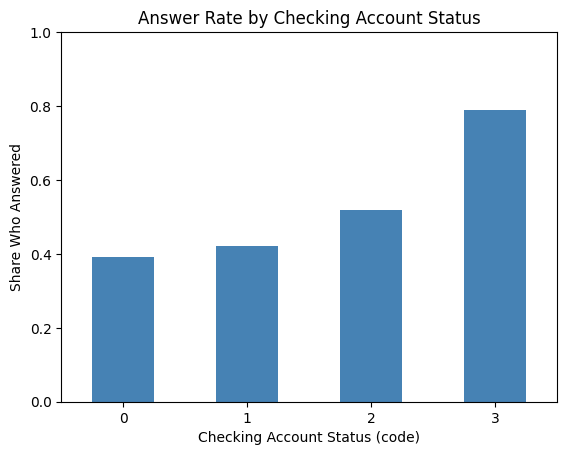

In [47]:
# Chart 3.1 🔧
# bar chart: answer rate by checking account status
chk_rate = df_clean.groupby("chk_acct", observed=True)["answered"].mean()
chk_rate.plot(kind="bar", color="steelblue")
plt.title("Answer Rate by Checking Account Status")
plt.xlabel("Checking Account Status (code)")
plt.ylabel("Share Who Answered")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.show()

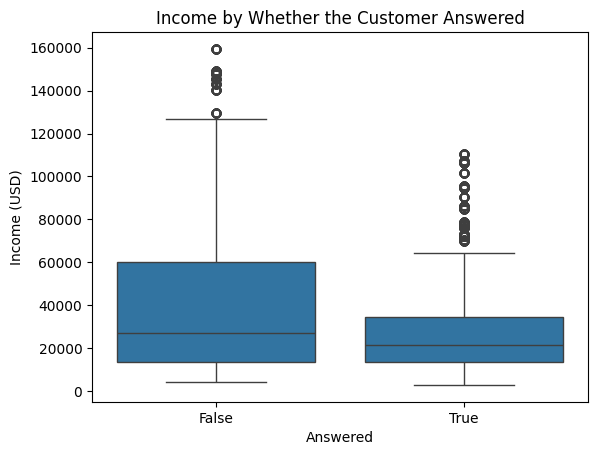

In [48]:
# Chart 3.2 🔧
# box plot: income by answered
sns.boxplot(data=df_clean, x="answered", y="income")
plt.title("Income by Whether the Customer Answered")
plt.xlabel("Answered")
plt.ylabel("Income (USD)")
plt.show()

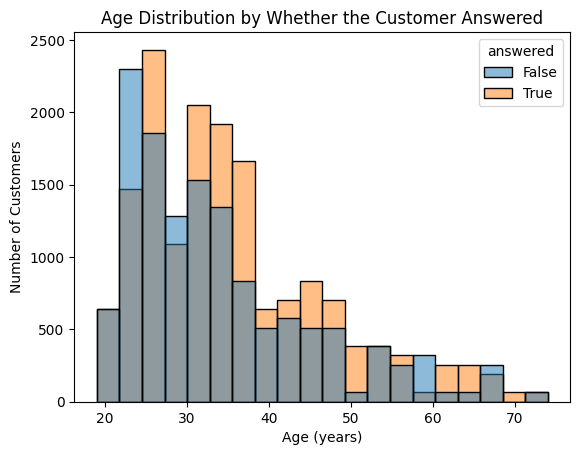

In [49]:
# Chart 3.3 🔧
# histogram: age by answered
sns.histplot(data=df_clean, x="age", hue="answered", bins=20)
plt.title("Age Distribution by Whether the Customer Answered")
plt.xlabel("Age (years)")
plt.ylabel("Number of Customers")
plt.show()

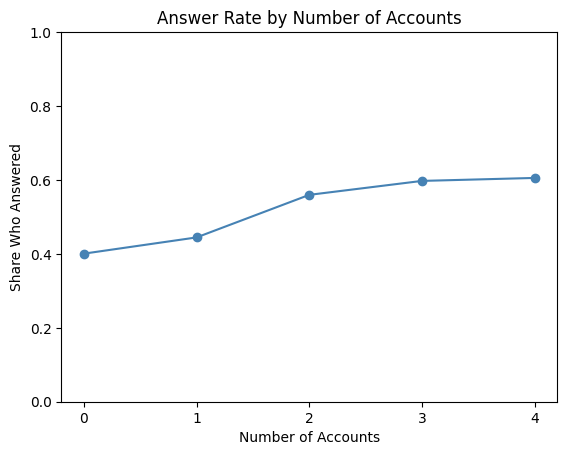

In [50]:
# Chart 3.4 🔧
# line chart: answer rate by number of accounts
accts_rate = df_clean.groupby("num_accts")["answered"].mean()
accts_rate.plot(kind="line", marker="o", color="steelblue")
plt.title("Answer Rate by Number of Accounts")
plt.xlabel("Number of Accounts")
plt.ylabel("Share Who Answered")
plt.xticks(range(5))
plt.ylim(0, 1)
plt.show()

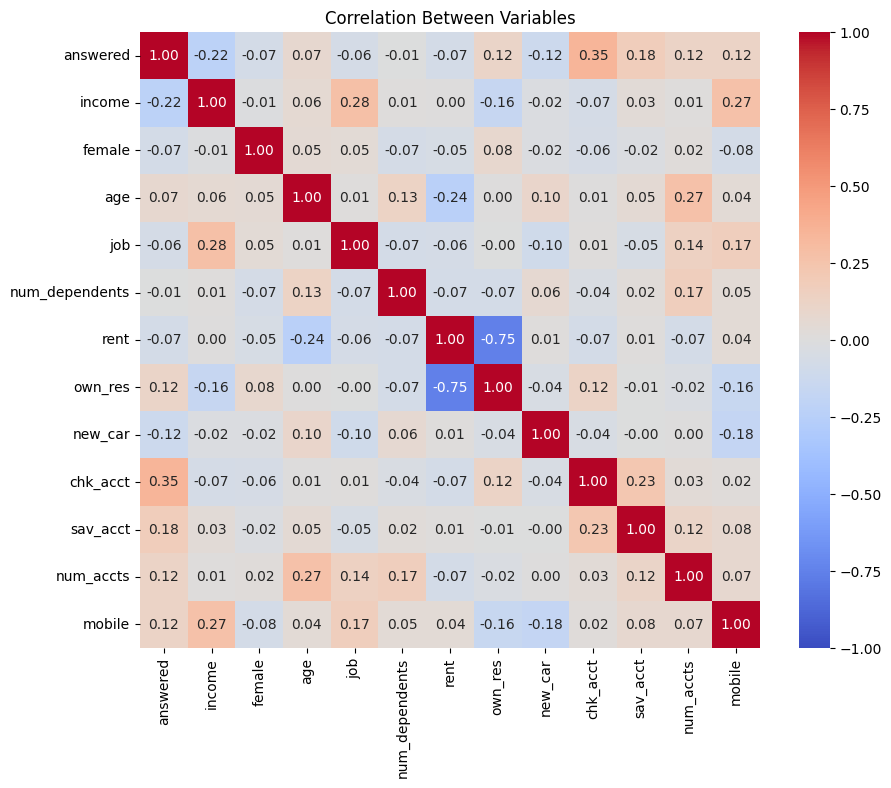

In [51]:
# Chart 3.5 🔧
# heatmap: correlation between all variables
plt.figure(figsize=(10, 8))
sns.heatmap(df_clean.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Between Variables")
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6. Checking account status has the strongest relationship, with a correlation of 0.35. Chart 3.1 shows the answer rate rise from about 0.4 at code 0 to about 0.8 at code 3. Income is next at -0.22, and Chart 3.2 shows a lower median income for customers who answered. Savings account status follows at 0.18.

3.7. Num_dependents is the weakest at -0.01. Age, job, female, and rent are also weak, between -0.07 and 0.07. I kept them all. Correlation only measures a straight-line relationship, and a tree can still find a useful split in a weak variable. The first tree splits on age twice.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [52]:
# base probability = share of customers who answered
base_prob = df_clean["answered"].mean()
print("Base probability of answering:", round(base_prob, 4))

Base probability of answering: 0.5467


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [53]:
# x has every variable except answered, y is answered
X = df_clean.drop(columns="answered")
y = df_clean["answered"]

# 70% train, 30% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 20645
Testing rows: 8848


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

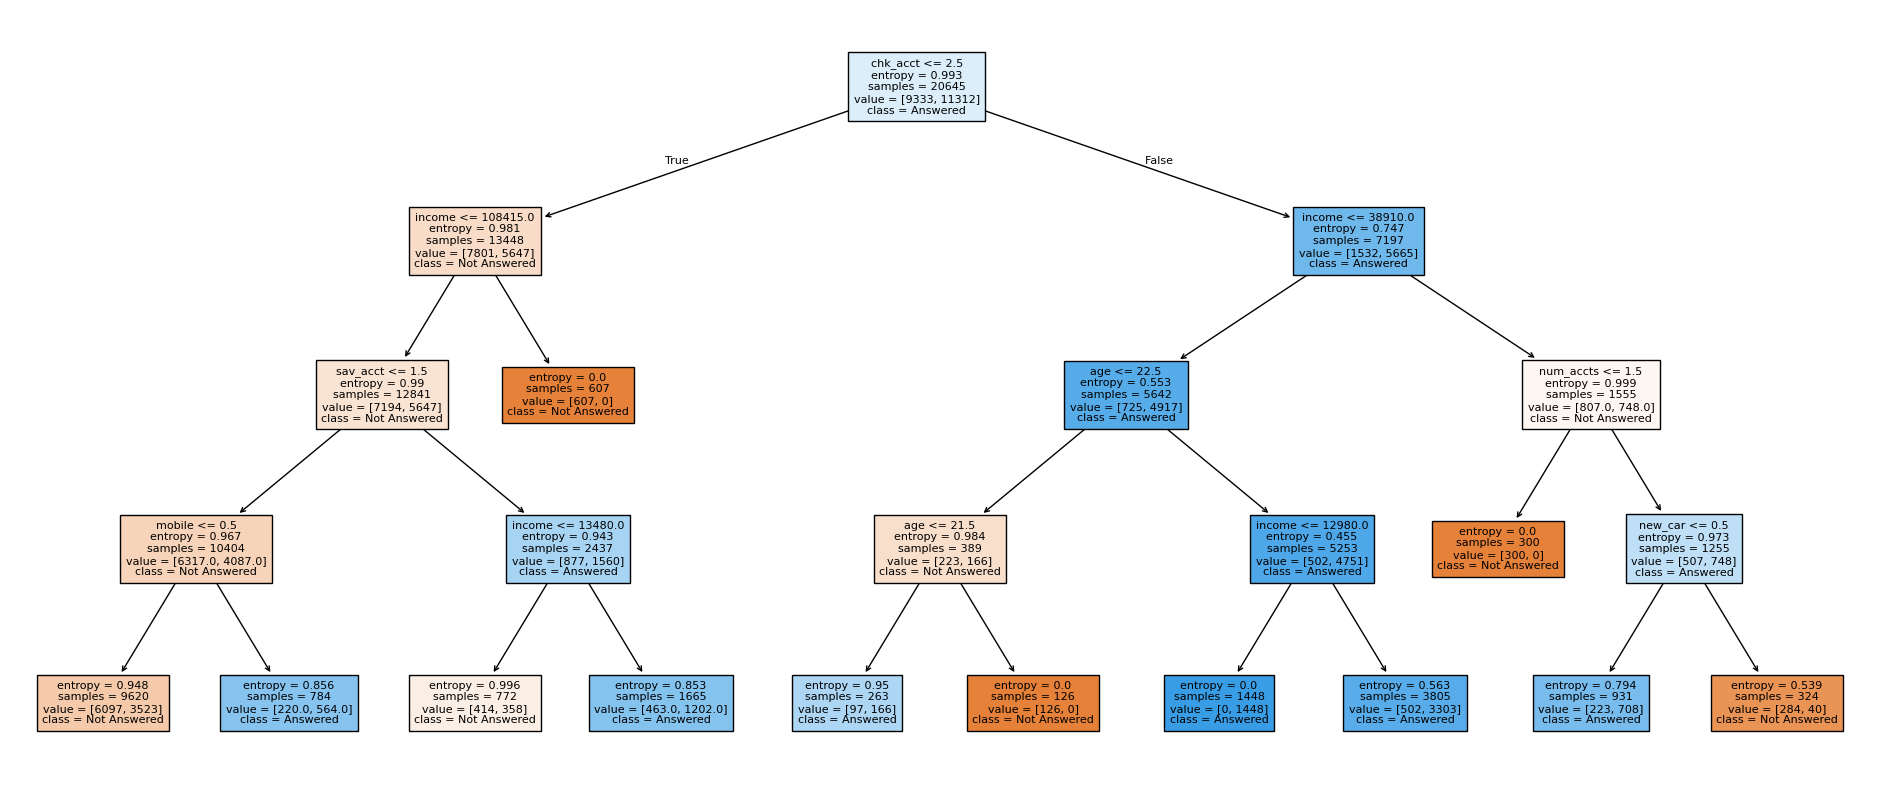

In [54]:
# build the tree
tree = DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=42)
tree.fit(X_train, y_train)

# show the tree
plt.figure(figsize=(24, 10))
plot_tree(tree, feature_names=X.columns, class_names=["Not Answered", "Answered"], filled=True, fontsize=8)
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [55]:
# accuracy on the test data
y_pred = tree.predict(X_test)
tree_acc = accuracy_score(y_test, y_pred)
print("Tree accuracy:", round(tree_acc, 4))
print("Difference from base probability:", round(tree_acc - base_prob, 4))

Tree accuracy: 0.7453
Difference from base probability: 0.1986


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The tree is accurate 0.7453 of the time on the test data. The base probability of answering is 0.5467. The difference is 0.1986, or about 20 percentage points.

2. Yes, for accuracy. The tree's accuracy is about 20 percentage points above the base probability. That is a meaningful gain for deciding whom to call. Accuracy ignores the cost of each kind of mistake, so Step 5 checks whether the gain carries into profit.


### 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

In [56]:
# rows are actual (False, True), columns are predicted (False, True)
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[3430  607]
 [1647 3164]]


Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

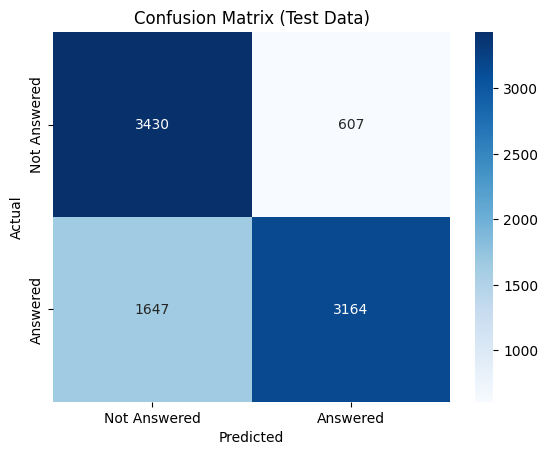

In [57]:
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Answered", "Answered"], yticklabels=["Not Answered", "Answered"])
plt.title("Confusion Matrix (Test Data)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [58]:
# pull the counts out of the confusion matrix
tn, fp, fn, tp = cm.ravel()

# true positives earn 75, false positives cost 25
model_profit = tp * 75 - fp * 25
print("True positives:", tp)
print("False positives:", fp)
print("Profit using the model:", model_profit)

True positives: 3164
False positives: 607
Profit using the model: 222125


### 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [59]:
# call every customer in the test data
answered_count = y_test.sum()
not_answered_count = len(y_test) - answered_count

default_profit = answered_count * 75 - not_answered_count * 25
print("Answered:", answered_count)
print("Did not answer:", not_answered_count)
print("Profit calling everyone:", default_profit)
print("Difference (model - call everyone):", model_profit - default_profit)

Answered: 4811
Did not answer: 4037
Profit calling everyone: 259900
Difference (model - call everyone): -37775


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. Calling only the customers the model picks earns \$222,125 on the test data. Calling all 8,848 test customers earns \$259,900. The model earns \$37,775 less.

2. Yes. The model gives up \$37,775 on 8,848 customers. It predicts that 1,647 customers who answered would not answer, and each of those is a lost \$75 profit. Those misses cost more than the \$25 the model saves on each of the 3,430 calls it correctly skips.


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [60]:
# new tree with more depth
tree2 = DecisionTreeClassifier(criterion="entropy", max_depth=6, random_state=42)
tree2.fit(X_train, y_train)

y_pred2 = tree2.predict(X_test)
print("Tuned tree accuracy:", round(accuracy_score(y_test, y_pred2), 4))

# profit for the tuned tree, same rules as 5.1
tn2, fp2, fn2, tp2 = confusion_matrix(y_test, y_pred2).ravel()
tuned_profit = tp2 * 75 - fp2 * 25
print("Profit using the tuned tree:", tuned_profit)

Tuned tree accuracy: 0.7916
Profit using the tuned tree: 236525


### 5.4 Apply the Model to New Customers

### Do the Following
- Import the "adviseinvest_new_customer_data.csv" file
- Copy and past the data cleanup steps from 2.1 and 2.2
- Using the tree model that you created in step 5.3, predict each customer for the target variable by feeding the new customer data into the model
- Predict the number of customers who will be yes/no for the target variable

In [61]:
# load the new customer data
df_new = pd.read_csv("https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_new_customer_data.csv")

# same cleanup as 2.1
df_new = df_new.drop_duplicates()
df_new = df_new[(df_new["income"] >= 0) & (df_new["age"] <= 100) & (df_new["num_accts"] <= 4)]
df_new = df_new.dropna()
df_new = df_new.drop(columns=["customer_id"])

# same type changes as 2.2 and 2.3
df_new["female"] = df_new["female"].astype(int)
df_new["new_car"] = df_new["new_car"].astype(int)
df_new["job"] = df_new["job"].astype("category")
df_new["chk_acct"] = df_new["chk_acct"].astype("category")
df_new["sav_acct"] = df_new["sav_acct"].astype("category")

# predict with the tuned tree
df_new["predicted_answer"] = tree2.predict(df_new)
print("New customers scored:", len(df_new))
print(df_new["predicted_answer"].value_counts())

New customers scored: 1000
predicted_answer
False    580
True     420
Name: count, dtype: int64


# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1 No. The original tree earned \$222,125 on the test data, and the tuned tree earned \$236,525. Calling every customer earned \$259,900, which beats both. The tuned tree raised accuracy from 0.7453 to 0.7916 and closed part of the gap, but it still earns less than calling everyone.

6.2 The company could score each customer when they book a call. On the new data, the tuned tree predicts 420 of 1,000 customers will answer and 580 will not. Reps could call the likely answerers first. The company should still call the rest, since skipping them lowered profit in Step 5.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [63]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"

[NbConvertApp] Converting notebook assignment_10_classification.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 7 image(s).
[NbConvertApp] Writing 968700 bytes to assignment_10_classification.html
